# **Testing system integration empirically**

**Goal:** with this notebook, one can test whether or not the architecture is capable of training a federated model.

**Preliminaries:**
- datasets published
- running BB01 deployment (either on Docker Compose or in Kubernetes)

**Test inputs:**
- aggregation_tree corresponding to actual deployment
- additional configurations:
    - test data for performance evaluation

**Test outputs:**
- downloadable model from `top-level-aggregator`'s MLFlow server
- credentials to be able to download model from the MLFLow server

**Acceptance criteria:**
- converging federated model

## **Test execution plan**
1. From this notebook, we iteratively call the `orchestrator` service's `start_training` endpoint.
2. Following this command, the system will run a *communication round*, a create an updated federated model.
3. We download the new version within each iteration, and we run a test with the resulted model to evaluate it.
4. After a number of iterations, the federated model shall reach convergence.

## Configuration

In [1]:
# I. DEPLOYMENT
# Deployment is either docker-compose or kubernetes:

DEPLOYMENT = "docker-compose"
#DEPLOYMENT = "kubernetes"


# II. NUMBER OF COMMUNICATION ROUNDS
# The number of communication rounds to run the integration test for:
NUM_ROUNDS = 100


# III. TEST DATA
# Test data shall be given in a npz file.
TEST_DATA_PATH = "../02_data/test/course_test.npz"

In [ ]:
AGGREGATION_TREE_DC_SHALLOW = {
    "processors": [
        {
            "uri": "http://data-processor-0:8000",
            "train_data_uri": "/data/train_data.npz",
            "forward_model_to": [
                "http://aggregator-top:8000"
            ]
        },
        {
            "uri": "http://data-processor-1:8000",
            "train_data_uri": "/data/train_data.npz",
            "forward_model_to": [
                "http://aggregator-top:8000"
            ]
        }
    ],
    "aggregators": [
        
        {
            "uri": "http://aggregator-top:8000",
            "forward_model_to": [],
            "top_level_aggregator": True,
            "aggregation_level": 0
        }
    ],
    "aggregation_algorithm": "fedavg"
}

AGGREGATION_TREE_DC_TWO_LEVELS = {
    "processors": [
        {
            "uri": "http://data-processor-0:8000",
            "train_data_uri": "/data/train_data.npz",
            "forward_model_to": ["http://aggregator-1:8000", "http://aggregator-2:8000"]
        },
        {
            "uri": "http://data-processor-1:8000",
            "train_data_uri": "/data/train_data.npz",
            "forward_model_to": ["http://aggregator-1:8000", "http://aggregator-2:8000"]
        }
    ],
    "aggregators": [
        {
            "uri":"http://aggregator-1:8000",
            "forward_model_to": ["http://aggregator-top:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 0
        },
        {
            "uri":"http://aggregator-2:8000",
            "forward_model_to": ["http://aggregator-top:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 0
        },
        {
            "uri":"http://aggregator-top:8000",
            "forward_model_to": [],
            "top_level_aggregator": True,
            "aggregation_level": 1
        }
    ],
    "aggregation_algorithm": "fedavg"
}

AGGREGATION_TREE_DC_THREE_LEVELS = {
    "processors": [
        {
            "uri": "http://data-processor-0:8000",
            "train_data_uri": "/data/train_data.npz",
            "forward_model_to": ["http://aggregator-1:8000", "http://aggregator-2:8000", "http://aggregator-3:8000", "http://aggregator-4:8000"]
        },
        {
            "uri": "http://data-processor-1:8000",
            "train_data_uri": "/data/train_data.npz",
            "forward_model_to": ["http://aggregator-1:8000", "http://aggregator-2:8000", "http://aggregator-3:8000", "http://aggregator-4:8000"]
        }
    ],
    "aggregators": [
        {
            "uri":"http://aggregator-1:8000",
            "forward_model_to": ["http://aggregator-5:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 0
        },
        {
            "uri":"http://aggregator-2:8000",
            "forward_model_to": ["http://aggregator-5:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 0
        },
        {
            "uri":"http://aggregator-3:8000",
            "forward_model_to": ["http://aggregator-6:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 0
        },
        {
            "uri":"http://aggregator-4:8000",
            "forward_model_to": ["http://aggregator-6:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 0
        },
        {
            "uri":"http://aggregator-5:8000",
            "forward_model_to": ["http://aggregator-top:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 1
        },
        {
            "uri":"http://aggregator-6:8000",
            "forward_model_to": ["http://aggregator-top:8000"],
            "top_level_aggregator": False,
            "aggregation_level": 1
        },
        {
            "uri":"http://aggregator-top:8000",
            "forward_model_to": [],
            "top_level_aggregator": True,
            "aggregation_level": 2
        }
    ],
    "aggregation_algorithm": "fedavg"
}

In [ ]:
AGGREGATION_TREE_DC = AGGREGATION_TREE_DC_TWO_LEVELS
AGGREGATION_TREE_K8S = {}

In [3]:
ORCHESTRATOR_URI_DC = "http://localhost:8100/"
ORCHESTRATOR_URI_K8S = "https://..."

In [4]:
AGGREGATION_TREE = AGGREGATION_TREE_DC if DEPLOYMENT == "docker-compose" else AGGREGATION_TREE_K8S
ORCHESTRATOR_URI = ORCHESTRATOR_URI_DC if DEPLOYMENT == "docker-compose" else ORCHESTRATOR_URI_K8S

## Preparation

In [5]:
import os

import requests
import mlflow

import numpy as np

import tensorflow as tf
import keras

/home/madbiker/miniconda3/envs/tf_env/lib/python3.12/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1789681517.711475  673730 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [6]:
test_data = np.load(TEST_DATA_PATH)

## Test Execution

In [7]:
losses = []
for i in range(NUM_ROUNDS):
    print(f"Communication round {i+1}/{NUM_ROUNDS}...")
    print("Training in progress...")
    response = requests.post(f"{ORCHESTRATOR_URI}/start_training",
                             json=AGGREGATION_TREE)
    model_dict = response.json()

    print("Downloading model from MLflow...")
    os.environ["MLFLOW_TRACKING_USERNAME"] = model_dict["model_username"]
    os.environ["MLFLOW_TRACKING_PASSWORD"] = model_dict["model_password"]
    mlflow.set_tracking_uri(model_dict["model_host_external"])
    nn = mlflow.keras.load_model(model_dict["model_id"])

    print("Evaluating model...")
    loss = tf.losses.binary_crossentropy(
        test_data["y_test"],
        nn.predict(test_data["x_test"]).reshape(-1)
    ).numpy()
    losses.append(loss)

Communication round 1/100...
Training in progress...
Evaluating model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


W0000 00:00:1789681533.287802  673730 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
/home/madbiker/miniconda3/envs/tf_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Communication round 2/100...
Training in progress...
Evaluating model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Communication round 3/100...
Training in progress...
Evaluating model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


/home/madbiker/miniconda3/envs/tf_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Communication round 4/100...
Training in progress...
Evaluating model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Communication round 5/100...
Training in progress...
Evaluating model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


...

/home/madbiker/miniconda3/envs/tf_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_50', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Communication round 99/100...
Training in progress...
Evaluating model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


/home/madbiker/miniconda3/envs/tf_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_51', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Communication round 100/100...
Training in progress...
Evaluating model...
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


/home/madbiker/miniconda3/envs/tf_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_52', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


## Test evaluation

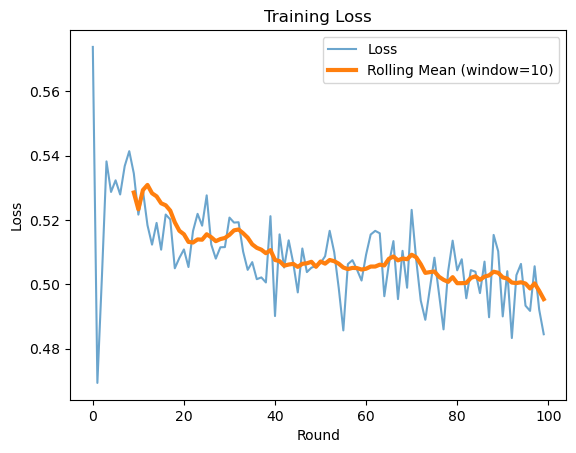

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

plt.plot(losses, label="Loss", alpha=0.66)
plt.plot(pd.Series(losses).rolling(10).mean(), linewidth=3,
         label="Rolling Mean (window=10)")
plt.xlabel("Round")
plt.ylabel("Loss")
plt.title("Test Loss")
plt.legend()
plt.show()

**Verdict:** The integration test ran successfully for 100 communication rounds, and the training loss is decreasing over the rounds. Test passed.